<a href="https://colab.research.google.com/github/Avazquezlopez1/proyecto-final-econometr-a-FINAL/blob/main/notebook/analisis_ventas_autos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


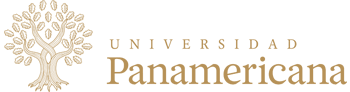

# PROYECTO FINAL

**Proyecto:** Análisis de pregunta económica

**Materia:** Fundamentos de Econometría, Universidad Panamericana

**Profesor:** Dr. Julio César Galindo López

**Integrantes:**
- Vázquez López Alvaro —  0267889
- Alvaro Fernandez Lozano — 0273215
- Diego Diez Gutierrez - 0274883
- Javier Martinez Manzo - 0273320




**Fecha de entrega:** 18 de Noviembre de 2026

# Venta de vehículos ligeros en México y multicolinealidad (2016–2025)

**Proyecto de Econometría — Universidad Panamericana**

**Pregunta:** ¿cómo se asocian las condiciones de financiamiento, ingreso, empleo y precios con la venta mensual de vehículos ligeros en México, y qué tanto dificulta la multicolinealidad medirlo?

**Unidad de análisis:** el mes, México (nacional).

**Datos:** 120 meses (enero 2016 – diciembre 2025) construidos con series oficiales de INEGI y Banco de México. Ver `Data/DICCIONARIO.md` en el repositorio.



## 1. Configuración

Cargamos las librerías del análisis: pandas y numpy para los datos, matplotlib y seaborn para las gráficas, statsmodels para las regresiones y pruebas de diagnóstico, y scikit-learn para Ridge y Lasso. También dejamos listo el formato de las gráficas y una carpeta para guardar las tablas.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson, jarque_bera

# Regularización (Ridge y Lasso)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
os.makedirs("tablas", exist_ok=True)

def guardar(fig, nombre):
    pass

Leemos la base con 120 observaciones mensuales de enero de 2016 a diciembre de 2025. El código busca el archivo en Colab y si no lo encuentra nos pide subirlo. También puede leerse directo de GitHub pegando el link en URL_DATOS.

In [2]:
import glob

# Carga de datos: busca automáticamente cualquier CSV que empiece con "dataset"
# (por ejemplo "dataset.csv" o "dataset 6.csv") en la carpeta content de Colab.
URL_DATOS = "https://raw.githubusercontent.com/Avazquezlopez1/proyecto-final-econometr-a-FINAL/refs/heads/main/Data/dataset%206.csv"
candidatos = sorted(glob.glob("/content/**/dataset*.csv", recursive=True) + glob.glob("dataset*.csv"))

if URL_DATOS:
    df = pd.read_csv(URL_DATOS)
elif candidatos:
    df = pd.read_csv(candidatos[0])
    print("Usando:", candidatos[0])
else:
    from google.colab import files
    print("No encontré el archivo. Selecciónalo en el botón de abajo:")
    subido = files.upload()
    if not subido:
        raise FileNotFoundError("No se subió ningún archivo. Vuelve a correr esta celda y elige el CSV.")
    df = pd.read_csv(next(iter(subido)))

print(f"{df.shape[0]} filas x {df.shape[1]} columnas | {df['fecha'].iloc[0]} a {df['fecha'].iloc[-1]}")
df.head()

120 filas x 19 columnas | 2016-01 a 2025-12


,fecha,anio,mes,ventas_vehiculos_total,ventas_automoviles,ventas_camiones_ligeros,inpc_var_anual,tasa_desocupacion,tasa_objetivo_promedio_mes,PIB IGAE,precio_real_automoviles,precio_real_gasolina,precio_real_seguro_auto,precio_real_tramites_vehiculares,precio_real_reparacion_auto,precio_real_transporte_publico,remesas_millones_usd,tasa_informalidad_til1,credito_automotriz_real
0,2016-01,2016,1,119833,75624,44209,2.61,4.1718,3.2500,95.0943,98.5860,76.8971,102.7971,107.9221,99.7773,99.3825,1976.3992,57.8313,97452.2054
1,2016-02,2016,2,111126,70884,40242,2.87,4.2550,3.4741,95.5430,98.8419,76.0916,102.5373,105.1758,99.7365,98.9468,2123.2209,57.2113,98162.3726
2,2016-03,2016,3,117252,75259,41993,2.60,4.1438,3.7500,95.1046,99.2519,75.5279,102.5753,103.5265,99.4555,99.1273,2235.7849,56.7479,98624.7352
3,2016-04,2016,4,118754,76557,42197,2.54,3.8230,3.7500,95.1859,99.5815,76.6217,103.0907,103.5677,99.8028,97.5724,2213.3934,57.1542,99853.3026
4,2016-05,2016,5,121879,77689,44190,2.60,3.9539,3.7500,95.5125,100.0572,77.0632,103.7436,104.0040,101.0976,97.6384,2532.8538,57.0818,100958.3408


## 2. Preparación de variables

- **Variable dependiente:** logaritmo de las ventas, para que cada coeficiente se lea como un cambio porcentual aproximado.
- **Escalas:** el crédito automotriz pasa a miles de millones de pesos y las remesas a miles de millones de dólares, para que sus coeficientes no salgan como 0.0000.
- **Ficticias de mes:** 11 indicadoras con enero como categoría de referencia (se omite una).
- **Ficticia COVID:** 1 en abril–junio de 2020, el cierre de actividades no esenciales.

In [3]:
df = df.rename(columns={"PIB IGAE": "igae"}) #cambia nombre para que sea mas facil el análisis
df["fecha"] = pd.to_datetime(df["fecha"]) #convierte a formato de fecha
df = df.sort_values("fecha").reset_index(drop=True) #ordena datos del mas antigua al reciente

df["log_ventas"] = np.log(df["ventas_vehiculos_total"]) #suiaviza valores extremos
df["credito_automotriz_mmdp"] = df["credito_automotriz_real"] / 1000      # miles de millones de pesos de 2018
df["remesas_mmdd"] = df["remesas_millones_usd"] / 1000                   # miles de millones de dólares
df["covid"] = df["fecha"].between("2020-04-01", "2020-06-30").astype(float) #para meses atipicos
df["tendencia"] = np.arange(len(df), dtype=float)                        # para ver si asociaciones se mantienen

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
dummies_mes = pd.get_dummies(df["mes"].map(lambda m: MESES[m - 1]), prefix="m", dtype=float) #convierte meses en numeros
dummies_mes = dummies_mes[[f"m_{m}" for m in MESES[1:]]]                 # enero = referencia
df = pd.concat([df, dummies_mes], axis=1)
CONTROLES = list(dummies_mes.columns) + ["covid"]

# Catálogo de explicativas: nombre corto, unidad y signo esperado (hipótesis).
CATALOGO = {
    "tasa_objetivo_promedio_mes":       ("Tasa objetivo Banxico",        "punto porcentual",         "-"),
    "inpc_var_anual":                   ("Inflación anual",              "punto porcentual",         "-"),
    "tasa_desocupacion":                ("Desocupación",                 "punto porcentual",         "-"),
    "igae":                             ("IGAE",                         "punto del índice",         "+"),
    "tasa_informalidad_til1":           ("Informalidad laboral",         "punto porcentual",         "-"),
    "credito_automotriz_mmdp":          ("Crédito automotriz real",      "mil millones de pesos",    "+"),
    "remesas_mmdd":                     ("Remesas",                      "mil millones de dólares",  "+"),
    "precio_real_automoviles":          ("Precio real autos",            "punto del índice",         "-"),
    "precio_real_gasolina":             ("Precio real gasolina",         "punto del índice",         "-"),
    "precio_real_seguro_auto":          ("Precio real seguro",           "punto del índice",         "-"),
    "precio_real_tramites_vehiculares": ("Precio real trámites",         "punto del índice",         "-"),
    "precio_real_reparacion_auto":      ("Precio real reparación",       "punto del índice",         "+"),
    "precio_real_transporte_publico":   ("Precio real transp. público",  "punto del índice",         "+"),
    # Se incluyen automáticamente cuando estén en dataset.csv:
    "tipo_cambio_fix":                  ("Tipo de cambio FIX",           "peso por dólar",           "-"),
    "confianza_consumidor":             ("Confianza del consumidor",     "punto del índice",         "+"),
}
X_TODAS = [v for v in CATALOGO if v in df.columns]
NOMBRE = {v: CATALOGO[v][0] for v in X_TODAS}
print(f"{len(X_TODAS)} variables explicativas disponibles:")
print(", ".join(NOMBRE[v] for v in X_TODAS))

13 variables explicativas disponibles:
Tasa objetivo Banxico, Inflación anual, Desocupación, IGAE, Informalidad laboral, Crédito automotriz real, Remesas, Precio real autos, Precio real gasolina, Precio real seguro, Precio real trámites, Precio real reparación, Precio real transp. público


### Hipótesis

Antes de estimar, planteamos el signo esperado de cada variable.

Esperamos que las ventas bajen cuando suben la tasa de interés (el crédito se encarece), la inflación (se pierde poder de compra), la desocupación y la informalidad (menos ingreso estable y menos acceso a crédito), y los precios de los autos, la gasolina, el seguro y los trámites (comprar y mantener un auto cuesta más).

Esperamos que suban con el IGAE (más actividad económica), con el crédito automotriz y las remesas (más financiamiento e ingreso de los hogares), y con los precios de la reparación y del transporte público, porque encarecen las alternativas a comprar un auto nuevo.

## 3. Exploración

### 3.1 Estadísticas descriptivas

Calculamos la media, desviación estándar, mínimo y máximo de cada variable para conocer su escala y rango antes de estimar. En promedio se vendieron 111 mil vehículos al mes, con un mínimo en abril de 2020 (COVID) y un máximo en diciembre de 2016.

In [4]:
desc = df[["ventas_vehiculos_total"] + X_TODAS].describe().T[["mean", "std", "min", "max"]]
desc.columns = ["Media", "Desv. est.", "Mínimo", "Máximo"]
desc.index = ["Ventas (unidades)"] + [NOMBRE[v] for v in X_TODAS]
desc.round(2).to_csv("tablas/descriptivos.csv")
desc.round(2)

,Media,Desv. est.,Mínimo,Máximo
Ventas (unidades),111161.02,23181.62,34927.00,192741.00
Tasa objetivo Banxico,7.44,2.39,3.25,11.25
Inflación anual,4.85,1.59,2.15,8.70
Desocupación,3.40,0.63,2.49,5.44
IGAE,99.58,4.79,76.16,106.17
Informalidad laboral,55.65,1.28,47.89,57.83
Crédito automotriz real,142.77,37.81,97.45,249.35
Remesas,3.95,1.22,1.98,6.23
Precio real autos,102.96,2.66,98.59,107.82
Precio real gasolina,91.69,6.28,75.53,103.35


### 3.2 Las ventas en el tiempo

Graficamos las ventas mensuales junto con su promedio móvil de 12 meses. Se ven dos rasgos que el modelo debe controlar: un patrón estacional que se repite cada año y la caída por el cierre de COVID en 2020, marcada en gris.

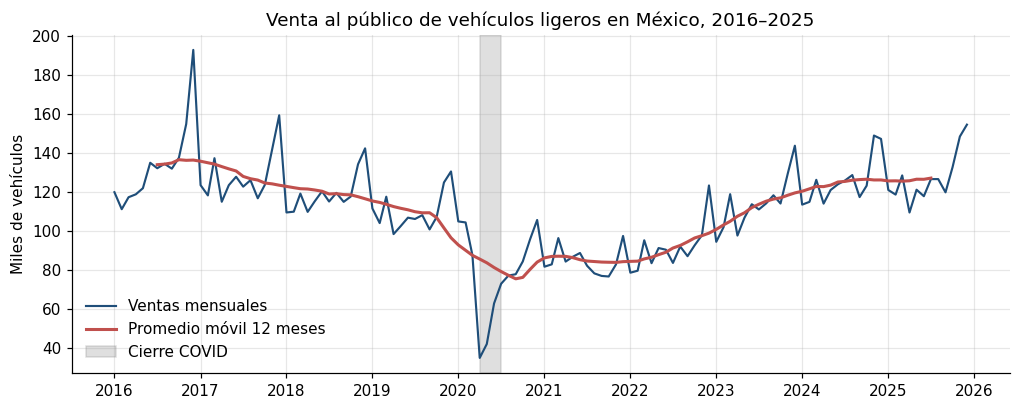

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df["fecha"], df["ventas_vehiculos_total"] / 1000, color="#1f4e79", lw=1.4, label="Ventas mensuales")
ax.plot(df["fecha"], df["ventas_vehiculos_total"].rolling(12, center=True).mean() / 1000,
        color="#c0504d", lw=2, label="Promedio móvil 12 meses")
ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-06-30"), color="grey", alpha=0.25, label="Cierre COVID")
ax.set_ylabel("Miles de vehículos")
ax.set_title("Venta al público de vehículos ligeros en México, 2016–2025")
ax.legend(loc="lower left", frameon=False)
guardar(fig, "01_ventas_tiempo")
plt.show()

Comparamos la distribución de las ventas en cada mes del año. Noviembre y diciembre concentran las ventas más altas, por el Buen Fin, los aguinaldos y las ofertas de cierre de año, mientras que enero, febrero y abril son los meses más bajos. Esto es la justificacion de incluir variables ficticias de mes en el modelo.

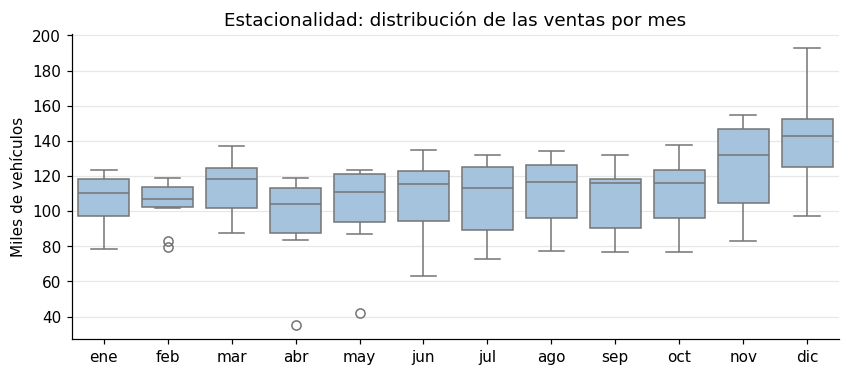

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.boxplot(x=df["mes"].map(lambda m: MESES[m - 1]), y=df["ventas_vehiculos_total"] / 1000,
            order=MESES, color="#9dc3e6", ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Miles de vehículos")
ax.set_title("Estacionalidad: distribución de las ventas por mes")
guardar(fig, "02_estacionalidad")
plt.show()

### 3.3 Relación de las ventas con cada variable

Graficamos el logaritmo de las ventas contra cada variable explicativa, con su correlación simple (r) en el título; los puntos rojos son los meses del cierre por COVID. Son una primera exploración antes de la regresión.

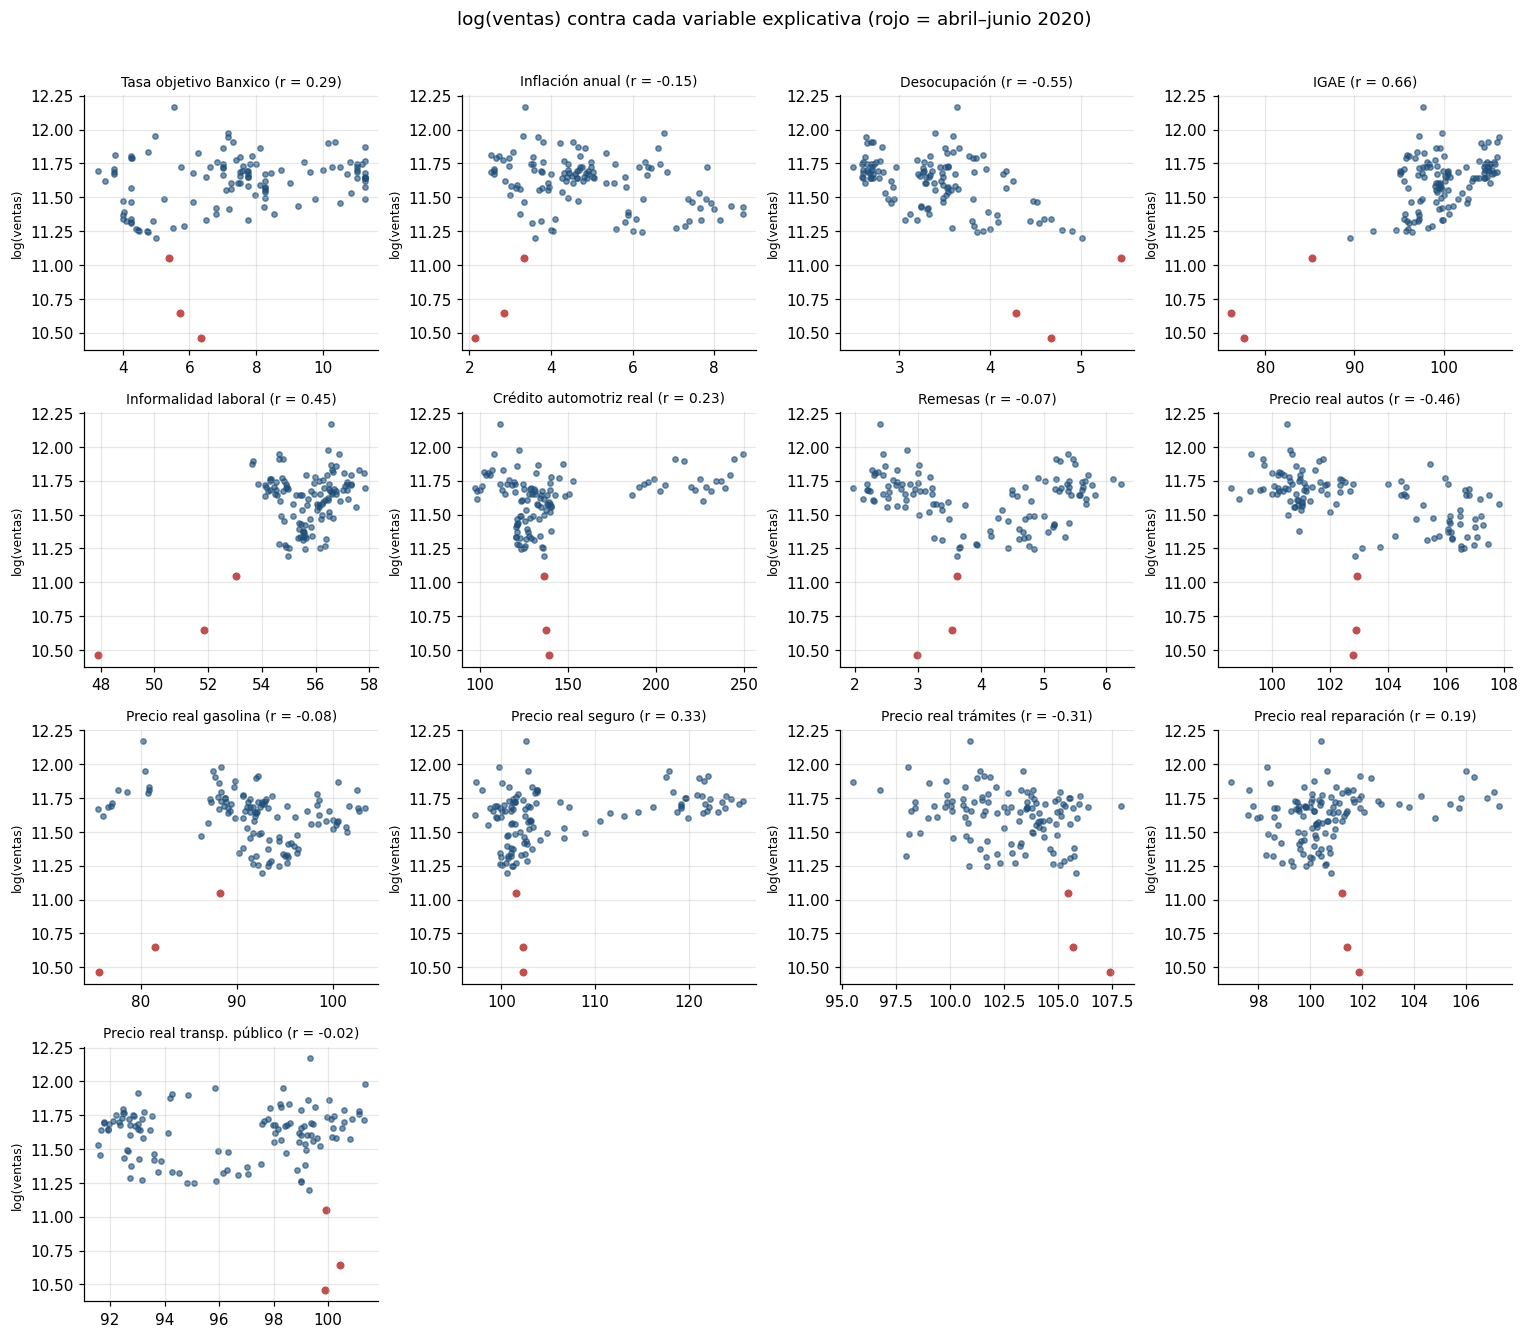

In [7]:
n = len(X_TODAS)
cols = 4
filas = int(np.ceil(n / cols))
fig, axes = plt.subplots(filas, cols, figsize=(14, 3 * filas))
for ax, v in zip(axes.flat, X_TODAS):
    ax.scatter(df[v], df["log_ventas"], s=12, alpha=0.6, color="#1f4e79")
    ax.scatter(df.loc[df["covid"] == 1, v], df.loc[df["covid"] == 1, "log_ventas"], s=18, color="#c0504d")
    r = df[[v, "log_ventas"]].corr().iloc[0, 1]
    ax.set_title(f"{NOMBRE[v]} (r = {r:.2f})", fontsize=9)
    ax.set_ylabel("log(ventas)", fontsize=8)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
fig.suptitle("log(ventas) contra cada variable explicativa (rojo = abril–junio 2020)", y=1.01)
fig.tight_layout()
guardar(fig, "03_dispersion")
plt.show()

### 3.4 Correlaciones entre explicativas

Calculamos la correlación entre cada par de variables explicativas y listamos los 10 pares más correlacionados, como primera señal de multicolinealidad. Destacan el IGAE con la desocupación (−0.85) y las remesas con el precio del transporte público (−0.85). Se complementa con el VIF.

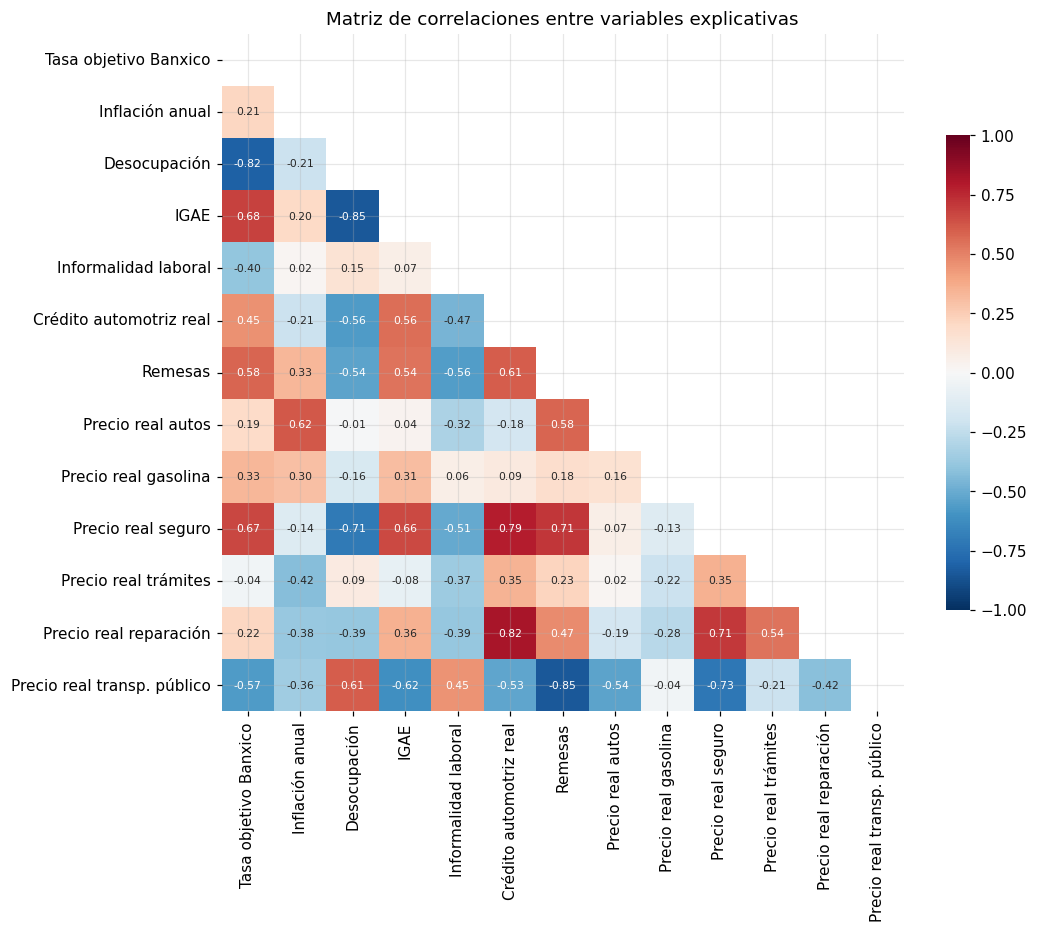

Los 10 pares más correlacionados:


,Variable 1,Variable 2,r
0,Precio real transp. público,Remesas,-0.85
1,IGAE,Desocupación,-0.85
2,Crédito automotriz real,Precio real reparación,0.82
3,Desocupación,Tasa objetivo Banxico,-0.82
4,Crédito automotriz real,Precio real seguro,0.79
5,Precio real seguro,Precio real transp. público,-0.73
6,Precio real seguro,Remesas,0.71
7,Precio real reparación,Precio real seguro,0.71
8,Precio real seguro,Desocupación,-0.71
9,IGAE,Tasa objetivo Banxico,0.68


In [8]:
corr = df[X_TODAS].corr()
corr_nombres = corr.rename(index=NOMBRE, columns=NOMBRE)
mascara = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_nombres, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Matriz de correlaciones entre variables explicativas")
guardar(fig, "04_correlaciones")
plt.show()

pares = corr.stack().reset_index()
pares.columns = ["Variable 1", "Variable 2", "r"]
pares = pares[pares["Variable 1"] < pares["Variable 2"]]
pares["|r|"] = pares["r"].abs()
pares = pares.sort_values("|r|", ascending=False).head(10)
pares[["Variable 1", "Variable 2"]] = pares[["Variable 1", "Variable 2"]].replace(NOMBRE)
print("Los 10 pares más correlacionados:")
pares[["Variable 1", "Variable 2", "r"]].round(2).reset_index(drop=True)

## 4. Regresión por MCO

Estimamos cuatro modelos por Mínimos Cuadrados Ordinarios (MCO), todos con esta forma:

$$\log(\text{ventas}_t) = \beta_0 + \sum_j \beta_j X_{jt} + \sum_{m=2}^{12} \gamma_m D_{mt} + \delta\,\text{COVID}_t + u_t$$

donde $t$ es el mes, $X_{jt}$ son las variables explicativas, $D_{mt}$ las ficticias de mes (enero es la referencia), $\text{COVID}_t$ la ficticia del cierre de 2020 y $u_t$ el error, es decir, todo lo que el modelo no explica. Cada $\beta_j$ indica en qué porcentaje aproximado cambian las ventas cuando $X_j$ aumenta una unidad, manteniendo lo demás constante.

**Errores estándar Newey-West.** El error estándar mide qué tan preciso es cada coeficiente, y de él dependen los intervalos de confianza y los valores p. La fórmula usual supone que el error de un mes no tiene relación con el del siguiente. En datos mensuales eso no se cumple: si un mes las ventas quedan por encima de lo que predice el modelo es probable que el siguiente también. Newey-West corrige el error estándar tomando en cuenta esa relación (aquí, hasta 4 meses hacia atrás) y las varianzas desiguales para no presentar los coeficientes como más precisos de lo que son. Los coeficientes no cambian, solo su precisión.

| Modelo | Qué incluye | Para qué sirve |
| --- | --- | --- |
| M1 Base | Tasa, inflación, desocupación, IGAE | Variables básicas |
| M2 Ingreso y crédito | M1 + informalidad, crédito, remesas | Agrega financiamiento e ingreso de los hogares |
| M3 Completo | Todas las explicativas | Muestra síntomas de la multicolinealidad |
| M4 Reducido | M3 - Desocupación, Precio del seguro, precio de reparación, precio de trámites  | Modelo principal que interpretamos |

M4 quita variables redundantes según la teoría: la desocupación, porque mide el mismo ciclo económico que el IGAE, y los precios de seguro, reparación y trámites, porque son costos de tener auto que se mueven juntos y junto con el crédito.

In [9]:
MODELOS = {
    "M1 Base": ["tasa_objetivo_promedio_mes", "inpc_var_anual", "tasa_desocupacion", "igae"],
    "M2 Ingreso y crédito": ["tasa_objetivo_promedio_mes", "inpc_var_anual", "tasa_desocupacion", "igae",
                             "tasa_informalidad_til1", "credito_automotriz_mmdp", "remesas_mmdd"],
    "M3 Completo": X_TODAS,
    "M4 Reducido": ["tasa_objetivo_promedio_mes", "inpc_var_anual", "igae", "tasa_informalidad_til1",
                    "credito_automotriz_mmdp", "remesas_mmdd", "precio_real_automoviles",
                    "precio_real_gasolina", "precio_real_transporte_publico"]
                   + [v for v in ["tipo_cambio_fix", "confianza_consumidor"] if v in X_TODAS],
}
REZAGOS_HAC = 4

def estimar(xs, datos=None, controles=CONTROLES, y="log_ventas"):
    datos = df if datos is None else datos
    X = sm.add_constant(datos[xs + controles].astype(float), has_constant="add")
    return sm.OLS(datos[y], X).fit(cov_type="HAC", cov_kwds={"maxlags": REZAGOS_HAC})

res = {nombre: estimar(xs) for nombre, xs in MODELOS.items()}
for nombre, r in res.items():
    print(f"{nombre:22s} k = {len(MODELOS[nombre]):2d}  R2 = {r.rsquared:.3f}  R2 ajustado = {r.rsquared_adj:.3f}")

M1 Base                k =  4  R2 = 0.721  R2 ajustado = 0.678
M2 Ingreso y crédito   k =  7  R2 = 0.885  R2 ajustado = 0.863
M3 Completo            k = 13  R2 = 0.947  R2 ajustado = 0.933
M4 Reducido            k =  9  R2 = 0.936  R2 ajustado = 0.922


### 4.1 Tabla comparativa de modelos

Ponemos los cuatro modelos lado a lado para ver cómo cambian los coeficientes al agregar variables. Cada celda muestra el coeficiente y, abajo entre paréntesis, su error estándar Newey-West: entre más pequeño, más preciso es el coeficiente. Las estrellas indican significancia estadística, es decir, qué tan seguros estamos de que la asociación no es cero (\*\*\* al 1%, \*\* al 5%, \* al 10%). El R² mide qué parte de la variación de las ventas explica el modelo, y el R² ajustado hace lo mismo pero penaliza agregar variables que aportan poco. Las ficticias de mes y la constante se estiman, pero no se muestran.

Trabajamos con un nivel de significancia de 5%; las estrellas al 10% se muestran solo como referencia.

In [10]:
def estrellas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def tabla_modelos(resultados, variables):
    filas = {}
    for v in variables + ["covid"]:
        coef, se = [], []
        for r in resultados.values():
            if v in r.params.index:
                coef.append(f"{r.params[v]:.4f}{estrellas(r.pvalues[v])}")
                se.append(f"({r.bse[v]:.4f})")
            else:
                coef.append("")
                se.append("")
        etiqueta = NOMBRE.get(v, "COVID (abr–jun 2020)")
        filas[etiqueta] = coef
        filas[etiqueta + " "] = se
    t = pd.DataFrame(filas, index=list(resultados)).T
    t.loc["Ficticias de mes"] = ["Sí"] * len(resultados)
    t.loc["Observaciones"] = [int(r.nobs) for r in resultados.values()]
    t.loc["R²"] = [f"{r.rsquared:.3f}" for r in resultados.values()]
    t.loc["R² ajustado"] = [f"{r.rsquared_adj:.3f}" for r in resultados.values()]
    return t

tabla = tabla_modelos(res, X_TODAS)
tabla.to_csv("tablas/modelos.csv")
tabla

,M1 Base,M2 Ingreso y crédito,M3 Completo,M4 Reducido
Tasa objetivo Banxico,-0.0202,-0.0164,0.0050,0.0140**
Tasa objetivo Banxico,(0.0142),(0.0135),(0.0078),(0.0067)
Inflación anual,-0.0482***,-0.0303***,0.0043,-0.0102*
Inflación anual,(0.0150),(0.0101),(0.0079),(0.0057)
Desocupación,-0.1946**,-0.1203**,0.0058,
Desocupación,(0.0984),(0.0487),(0.0228),
IGAE,0.0061,0.0452***,0.0349***,0.0433***
IGAE,(0.0190),(0.0076),(0.0052),(0.0048)
Informalidad laboral,,0.0169,0.0468***,0.0328***
Informalidad laboral,,(0.0151),(0.0098),(0.0120)


### 4.2 Interpretación de los coeficientes

Traducimos los coeficientes del modelo principal (M4) a porcentajes. Como las ventas están en logaritmo, un aumento de una unidad en $X$ se asocia con un cambio de $100 \cdot (e^{\beta} - 1)\%$ en las ventas, manteniendo constantes las demás variables. La tabla muestra ese efecto con su intervalo de confianza al 95% (el rango de valores compatible con los datos), el efecto de un cambio "típico" en $X$ (una desviación estándar), el valor p (entre más bajo, más evidencia de que la asociación no es cero) y si el signo obtenido coincide con el que esperábamos según la teoría.

In [11]:
MODELO_FINAL = "M4 Reducido"   # cámbienlo si eligen otra especificación

def interpretar(r, xs):
    ic = r.conf_int()
    filas = []
    for v in xs:
        b, p = r.params[v], r.pvalues[v]
        efecto = 100 * (np.exp(b) - 1)
        efecto_de = 100 * (np.exp(b * df[v].std()) - 1)
        esperado = CATALOGO[v][2]
        obtenido = "+" if b > 0 else "-"
        filas.append({
            "Variable": NOMBRE[v],
            "Unidad de X": CATALOGO[v][1],
            "β": round(b, 4),
            "Efecto por unidad (%)": round(efecto, 2),
            "IC 95% (%)": f"[{100*(np.exp(ic.loc[v,0])-1):.2f}, {100*(np.exp(ic.loc[v,1])-1):.2f}]",
            "Efecto por 1 desv. est. (%)": round(efecto_de, 2),
            "p": round(p, 3),
            "Signo esperado": esperado,
            "¿Coincide?": "Sí" if esperado == obtenido else "No",
        })
    return pd.DataFrame(filas)

interp = interpretar(res[MODELO_FINAL], MODELOS[MODELO_FINAL])
interp.to_csv("tablas/interpretacion_modelo_final.csv", index=False)
interp

,Variable,Unidad de X,β,Efecto por unidad (%),IC 95% (%),Efecto por 1 desv. est. (%),p,Signo esperado,¿Coincide?
0,Tasa objetivo Banxico,punto porcentual,0.0140,1.41,"[0.08, 2.76]",3.42,0.038,-,No
1,Inflación anual,punto porcentual,-0.0102,-1.02,"[-2.12, 0.10]",-1.62,0.074,-,Sí
2,IGAE,punto del índice,0.0433,4.43,"[3.45, 5.42]",23.06,0.000,+,Sí
3,Informalidad laboral,punto porcentual,0.0328,3.33,"[0.93, 5.79]",4.30,0.006,-,No
4,Crédito automotriz real,mil millones de pesos,-0.0002,-0.02,"[-0.15, 0.10]",-0.92,0.704,+,No
5,Remesas,mil millones de dólares,-0.0934,-8.91,"[-13.97, -3.56]",-10.78,0.001,+,No
6,Precio real autos,punto del índice,-0.0119,-1.19,"[-2.86, 0.51]",-3.12,0.170,-,Sí
7,Precio real gasolina,punto del índice,-0.0101,-1.01,"[-1.25, -0.76]",-6.16,0.000,-,Sí
8,Precio real transp. público,punto del índice,-0.0050,-0.50,"[-1.92, 0.95]",-1.56,0.499,+,No


Cuatro de los nueve coeficientes tienen el signo esperado: IGAE, inflación, precio de los autos y precio de la gasolina. Los otros cinco no, y tienen explicaciones posibles.

La tasa de interés sale positiva probablemente por causalidad inversa: Banxico subió la tasa en 2022–2023, justo cuando las ventas se recuperaban de la escasez de chips de 2021–2022, un choque de oferta que el modelo no incluye.

La informalidad sale positiva por 2020: al excluir ese año deja de ser significativa (esto en la sección 6).

Las remesas y el crédito cambian de signo al agregar la tendencia, lo que sugiere que su asociación era crecimiento común en el tiempo.

El crédito y el transporte público no son significativos.

### 4.3 ¿Qué tan estables son los coeficientes entre modelos?

Graficamos el coeficiente de las cuatro variables principales en cada modelo: el punto es la estimación y la línea, su intervalo de confianza al 95%. Si la línea cruza el cero, no podemos descartar que la asociación sea nula. Al pasar del modelo base (M1) al completo (M3), la tasa de interés y la desocupación cambian de signo y sus intervalos se mueven hacia el cero, aunque el R² sube. Este es el síntoma clásico de la multicolinealidad: el modelo explica más, pero sus coeficientes individuales se vuelven inestables.

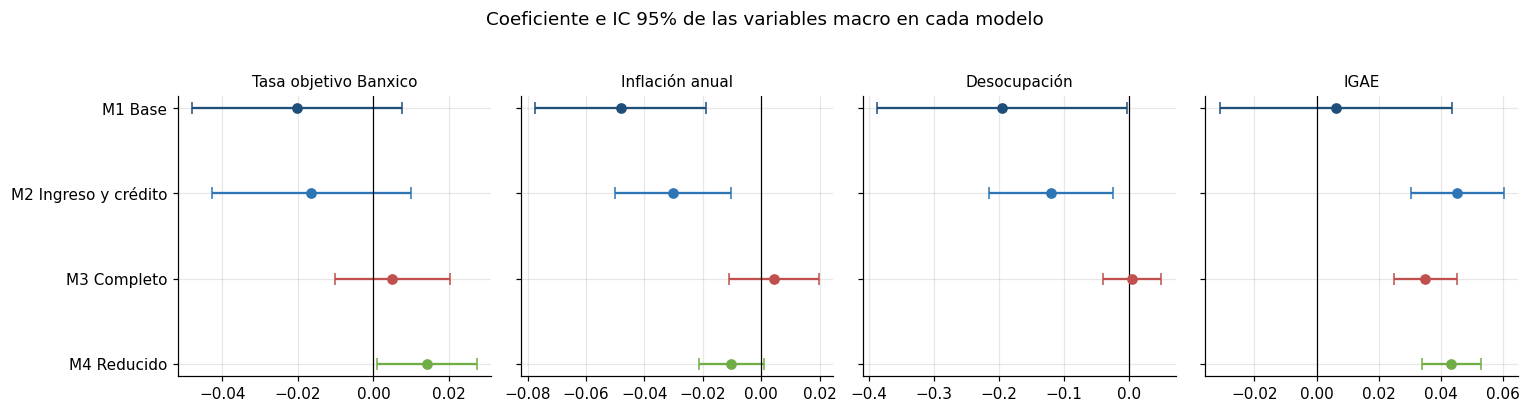

In [12]:
FOCO = ["tasa_objetivo_promedio_mes", "inpc_var_anual", "tasa_desocupacion", "igae"]
fig, axes = plt.subplots(1, len(FOCO), figsize=(14, 3.6), sharey=True)
colores = ["#1f4e79", "#2e75b6", "#c0504d", "#70ad47"]
for ax, v in zip(axes, FOCO):
    for i, (nombre, r) in enumerate(res.items()):
        if v in r.params.index:
            lo, hi = r.conf_int().loc[v]
            ax.errorbar(r.params[v], i, xerr=[[r.params[v] - lo], [hi - r.params[v]]], fmt="o",
                        color=colores[i], capsize=4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(NOMBRE[v], fontsize=10)
    ax.set_yticks(range(len(res)))
    ax.set_yticklabels(list(res))
axes[0].invert_yaxis()  # ejes compartidos: se invierte una sola vez (M1 arriba)
fig.suptitle("Coeficiente e IC 95% de las variables macro en cada modelo", y=1.03)
fig.tight_layout()
guardar(fig, "05_estabilidad_coeficientes")
plt.show()

## 5. Diagnóstico

### 5.1 Multicolinealidad: factor de inflación de varianza (VIF)

El VIF mide cuánto aumenta la imprecisión de un coeficiente porque esa variable se parece a las demás del modelo. Se calcula como

$$\text{VIF}_j = \frac{1}{1 - R^2_j}$$

donde $R^2_j$ indica qué tanto se puede predecir la variable $X_j$ con las otras variables del modelo. Un VIF de 1 significa que no comparte información con las demás; un VIF de 10 significa que la varianza de su coeficiente es 10 veces mayor que si fuera independiente. Comparamos el modelo completo (M3) con el reducido (M4). Usamos los umbrales de 5 y 10 solo para señal de alerta, no para eliminar variables.

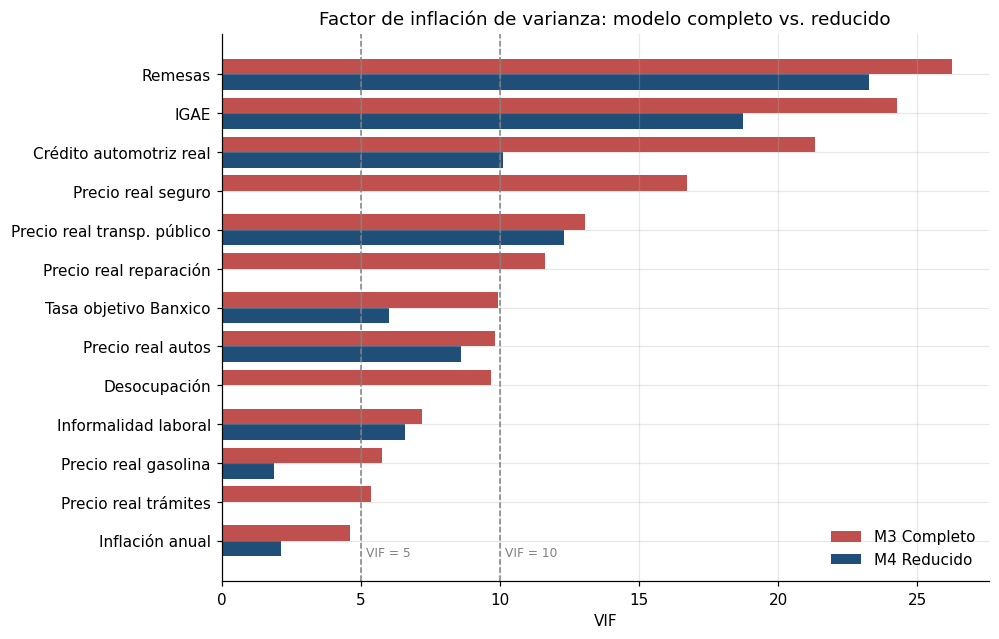

,M3 Completo,M4 Reducido
Remesas,26.3,23.3
IGAE,24.3,18.7
Crédito automotriz real,21.3,10.1
Precio real seguro,16.7,NaN
Precio real transp. público,13.1,12.3
Precio real reparación,11.6,NaN
Tasa objetivo Banxico,9.9,6.0
Precio real autos,9.8,8.6
Desocupación,9.7,NaN
Informalidad laboral,7.2,6.6


In [13]:
def vif(xs, controles=CONTROLES):
    X = sm.add_constant(df[xs + controles].astype(float), has_constant="add")
    valores = {v: variance_inflation_factor(X.values, X.columns.get_loc(v)) for v in xs}
    return pd.Series(valores)

vifs = pd.DataFrame({m: vif(MODELOS[m]) for m in ["M3 Completo", "M4 Reducido"]})
vifs.index = [NOMBRE[v] for v in vifs.index]
vifs = vifs.sort_values("M3 Completo", ascending=False)
vifs.round(1).to_csv("tablas/vif.csv")

fig, ax = plt.subplots(figsize=(9, 0.42 * len(vifs) + 1))
y = np.arange(len(vifs))
ax.barh(y - 0.2, vifs["M3 Completo"], height=0.4, color="#c0504d", label="M3 Completo")
ax.barh(y + 0.2, vifs["M4 Reducido"].fillna(0), height=0.4, color="#1f4e79", label="M4 Reducido")
for umbral in (5, 10):
    ax.axvline(umbral, color="grey", ls="--", lw=1)
    ax.text(umbral + 0.2, len(vifs) - 0.6, f"VIF = {umbral}", fontsize=8, color="grey")
ax.set_yticks(y)
ax.set_yticklabels(vifs.index)
ax.invert_yaxis()
ax.set_xlabel("VIF")
ax.set_title("Factor de inflación de varianza: modelo completo vs. reducido")
ax.legend(frameon=False, loc="lower right")
guardar(fig, "06_vif")
plt.show()
vifs.round(1)

### 5.2 Experimento: ¿qué pasa al quitar una variable redundante?

Partimos del modelo completo (M3), quitamos una variable a la vez entre las que tienen VIF mayor a 5 y medimos cómo cambia el error estándar de las cuatro variables macro. Si el error estándar baja, la variable quitada compartía información con ellas y las volvía menos precisas. Si sube, la variable explicaba una parte importante de las ventas y quitarla deja más variación sin explicar. La tabla también muestra el R² ajustado de cada versión, para ver cuánto poder explicativo se pierde.

In [14]:
filas = []
base = res["M3 Completo"]
candidatas = vifs.index[vifs["M3 Completo"] > 5]
inv = {nombre: v for v, nombre in NOMBRE.items()}
for nombre_v in candidatas:
    v = inv[nombre_v]
    xs = [x for x in MODELOS["M3 Completo"] if x != v]
    r = estimar(xs)
    fila = {"Variable eliminada": nombre_v, "R² ajustado": round(r.rsquared_adj, 3)}
    for f in FOCO:
        if f in xs:
            fila[f"Cambio en EE de {NOMBRE[f]} (%)"] = round(100 * (r.bse[f] / base.bse[f] - 1), 1)
    filas.append(fila)
experimento = pd.DataFrame(filas)
experimento.to_csv("tablas/experimento_quitar_variables.csv", index=False)
print(f"R² ajustado del modelo completo: {base.rsquared_adj:.3f}")
experimento

R² ajustado del modelo completo: 0.933


,Variable eliminada,R² ajustado,Cambio en EE de Tasa objetivo Banxico (%),Cambio en EE de Inflación anual (%),Cambio en EE de Desocupación (%),Cambio en EE de IGAE (%)
0,Remesas,0.921,0.2,11.6,37.8,21.0
1,IGAE,0.908,24.7,25.6,63.8,NaN
2,Crédito automotriz real,0.932,-11.6,-16.9,3.3,3.2
3,Precio real seguro,0.920,-9.0,-10.0,27.7,-3.8
4,Precio real transp. público,0.934,-1.5,1.3,1.3,-1.0
5,Precio real reparación,0.933,3.8,-20.8,2.5,-1.5
6,Tasa objetivo Banxico,0.934,NaN,3.3,0.3,4.4
7,Precio real autos,0.931,-2.9,-16.5,9.2,-0.4
8,Desocupación,0.934,-5.1,-0.8,NaN,-1.6
9,Informalidad laboral,0.923,4.9,13.6,17.4,-3.7


### 5.3 Supuestos sobre los residuos del modelo final

Los residuos son la diferencia entre las ventas reales y las que predice el modelo, es decir, lo que el modelo no logra explicar. Para confiar en los resultados, revisamos que cumplan ciertos supuestos con cuatro pruebas. Cada una parte de una hipótesis nula que dice que el supuesto se cumple; si el valor p es menor a 0.05, hay evidencia de que no se cumple.

La prueba de Breusch-Pagan revisa si el modelo se equivoca más o menos lo mismo en todos los meses o si en algunos se equivoca mucho más (heterocedasticidad).

Durbin-Watson revisa si el error de un mes se parece al del mes siguiente: su resultado va de 0 a 4, y un valor cercano a 2 indica que no se parecen, mientras que uno menor a 2 indica que sí(autocorrelación).

Ljung-Box hace la misma revisión pero comparando con los 12 meses anteriores, lo que es útil en datos mensuales.

Jarque-Bera revisa si los errores tienen forma de campana (distribución normal).

Además, reportamos el número de condición, una medida general de multicolinealidad del modelo: entre más alto, más se parecen las variables entre sí.

En el modelo final (M4), los errores son parejos (Breusch-Pagan, p = 0.55) y tienen forma de campana (Jarque-Bera, p = 0.87), pero sí están relacionados de un mes a otro (Durbin-Watson ≈ 0.95; Ljung-Box, p < 0.01). Por eso usamos errores estándar Newey-West, que corrigen precisamente esa relación entre meses.

In [15]:
def pruebas(r):
    bp = het_breuschpagan(r.resid, r.model.exog)
    jb = jarque_bera(r.resid)
    lb = acorr_ljungbox(r.resid, lags=[12], return_df=True)
    return {
        "Breusch-Pagan (p)": round(bp[1], 3),
        "Durbin-Watson": round(durbin_watson(r.resid), 2),
        "Ljung-Box 12 (p)": round(float(lb["lb_pvalue"].iloc[0]), 3),
        "Jarque-Bera (p)": round(jb[1], 3),
        "Número de condición": round(np.linalg.cond(r.model.exog), 0),
    }

diag = pd.DataFrame({m: pruebas(r) for m, r in res.items()})
diag.to_csv("tablas/diagnostico.csv")
diag

,M1 Base,M2 Ingreso y crédito,M3 Completo,M4 Reducido
Breusch-Pagan (p),0.000,0.482,0.407,0.545
Durbin-Watson,0.610,0.650,1.190,0.950
Ljung-Box 12 (p),0.000,0.000,0.000,0.000
Jarque-Bera (p),0.373,0.343,0.756,0.873
Número de condición,7309.000,22606.000,85006.000,54629.000


### 5.4 Gráficas de los residuos

Estas cuatro gráficas muestran visualmente lo que revisamos con las pruebas anteriores.

La primera compara las ventas reales con las que predice el modelo: si las dos líneas van juntas, el modelo reproduce bien el comportamiento de las ventas.

La segunda muestra los residuos a lo largo del tiempo.

La tercera es un histograma de los residuos, que debe tener forma de campana. La cuarta muestra la autocorrelación, qué tanto se parece el error de un mes al de 1, 2, 3… hasta 24 meses antes. Las barras que salen de la franja gris indican una relación significativa entre meses.

En el modelo final, las ventas ajustadas siguen de cerca a las reales, incluida la caída por COVID, y los residuos tienen forma de campana. Sin embargo, las barras de los primeros 3 meses salen de la franja gris: el error de un mes sí se parece al de los meses cercanos. Esto confirma la autocorrelación detectada por Durbin-Watson y Ljung-Box, y justifica usar errores estándar Newey-West.

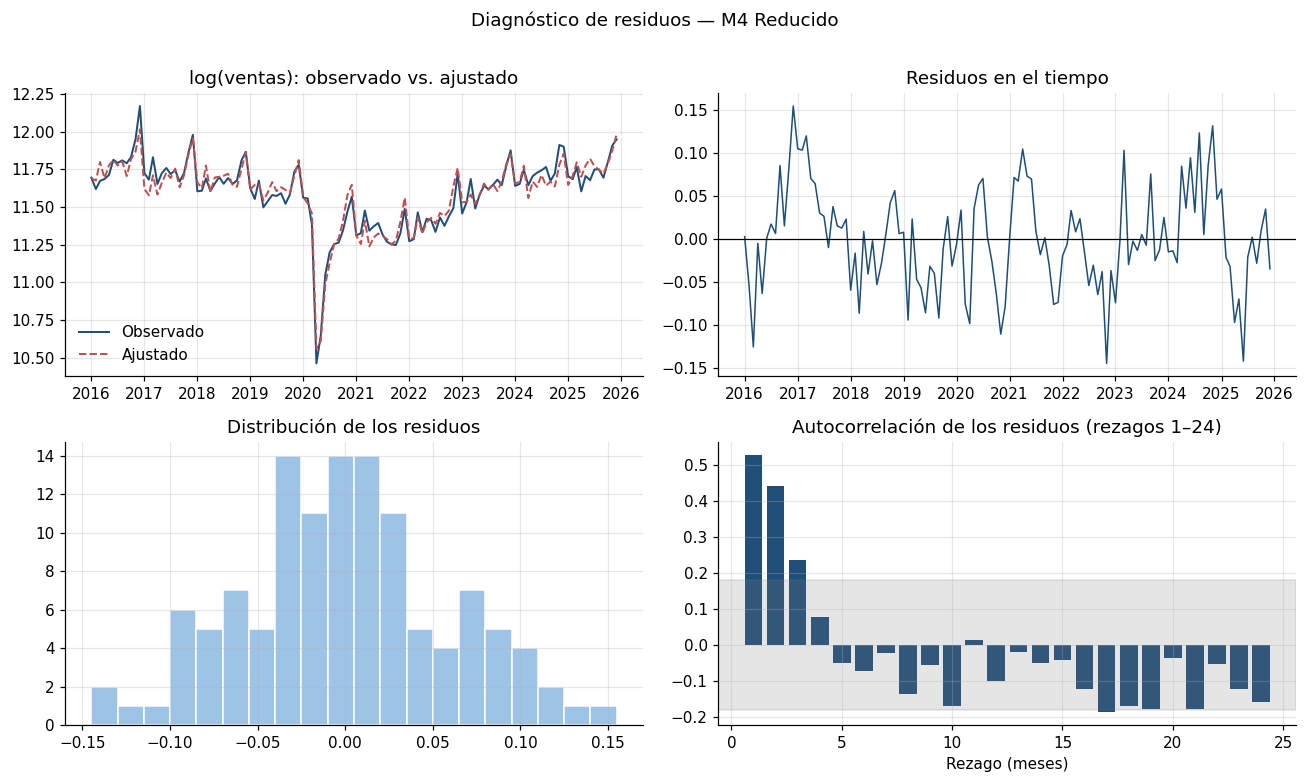

In [16]:
r = res[MODELO_FINAL]
resid = r.resid
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

axes[0, 0].plot(df["fecha"], df["log_ventas"], color="#1f4e79", lw=1.3, label="Observado")
axes[0, 0].plot(df["fecha"], r.fittedvalues, color="#c0504d", lw=1.3, ls="--", label="Ajustado")
axes[0, 0].set_title("log(ventas): observado vs. ajustado")
axes[0, 0].legend(frameon=False)

axes[0, 1].plot(df["fecha"], resid, color="#1f4e79", lw=1)
axes[0, 1].axhline(0, color="black", lw=0.8)
axes[0, 1].set_title("Residuos en el tiempo")

axes[1, 0].hist(resid, bins=20, color="#9dc3e6", edgecolor="white")
axes[1, 0].set_title("Distribución de los residuos")

rezagos = range(1, 25)
acf = [resid.autocorr(k) for k in rezagos]
banda = 1.96 / np.sqrt(len(resid))
axes[1, 1].bar(rezagos, acf, color="#1f4e79")
axes[1, 1].axhspan(-banda, banda, color="grey", alpha=0.2)
axes[1, 1].set_title("Autocorrelación de los residuos (rezagos 1–24)")
axes[1, 1].set_xlabel("Rezago (meses)")

fig.suptitle(f"Diagnóstico de residuos — {MODELO_FINAL}", y=1.01)
fig.tight_layout()
guardar(fig, "07_residuos")
plt.show()

## 6. Robustez: ¿qué decisión de modelado podría cambiar la conclusión?

Un resultado es robusto si se mantiene aunque cambiemos alguna decisión razonable del modelo. Volvemos a estimar el modelo final cambiando una decisión a la vez. Primero agregamos una tendencia lineal (una variable que solo cuenta los meses), porque si dos variables crecen juntas con el tiempo pueden parecer relacionadas aunque no lo estén (regresión espuria).

 Después usamos la desocupación en lugar del IGAE, excluimos todo 2020 por el COVID y usamos errores estándar convencionales en lugar de Newey-West.

El IGAE y el precio de la gasolina mantienen su signo y significancia en todas las versiones, así que son los resultados más sólidos. La tendencia es la decisión que más cambia la conclusión: con ella, el efecto negativo de las remesas desaparece y el crédito automotriz se vuelve positivo y significativo, como predice la teoría. Esto indica que parte de la asociación de esas variables era solo crecimiento común en el tiempo.


In [17]:
xs_final = MODELOS[MODELO_FINAL]
xs_desoc = [("tasa_desocupacion" if v == "igae" else v) for v in xs_final]
sin_2020 = df[df["anio"] != 2020].reset_index(drop=True)

rob = {
    "Final": res[MODELO_FINAL],
    "+ Tendencia": estimar(xs_final, controles=CONTROLES + ["tendencia"]),
    "Desocupación en vez de IGAE": estimar(xs_desoc),
    "Sin 2020": estimar(xs_final, datos=sin_2020, controles=[c for c in CONTROLES if c != "covid"]),
}
convencional = sm.OLS(df["log_ventas"], sm.add_constant(df[xs_final + CONTROLES].astype(float))).fit()
rob["EE convencionales"] = convencional

tabla_rob = tabla_modelos(rob, list(dict.fromkeys(xs_final + ["tasa_desocupacion"])))
tabla_rob.to_csv("tablas/robustez.csv")
tabla_rob

,Final,+ Tendencia,Desocupación en vez de IGAE,Sin 2020,EE convencionales
Tasa objetivo Banxico,0.0140**,0.0143**,0.0418***,0.0192**,0.0140**
Tasa objetivo Banxico,(0.0067),(0.0066),(0.0113),(0.0094),(0.0062)
Inflación anual,-0.0102*,-0.0174***,-0.0112,-0.0121**,-0.0102*
Inflación anual,(0.0057),(0.0044),(0.0076),(0.0054),(0.0055)
IGAE,0.0433***,0.0446***,,0.0340***,0.0433***
IGAE,(0.0048),(0.0059),,(0.0114),(0.0055)
Informalidad laboral,0.0328***,0.0175,0.0678***,0.0117,0.0328***
Informalidad laboral,(0.0120),(0.0150),(0.0253),(0.0109),(0.0121)
Crédito automotriz real,-0.0002,0.0034***,0.0012,0.0002,-0.0002
Crédito automotriz real,(0.0006),(0.0008),(0.0008),(0.0006),(0.0005)


## 7. Ridge y Lasso: regularización frente a la multicolinealidad

Cuando metemos todas las variables (M3), varias se parecen mucho entre sí y MCO no logra separar el efecto de cada una. los coeficientes se vuelven inestables, cambian de signo o salen exagerados.

Ridge y Lasso son variantes de la regresión que agregan una penalización a los coeficientes grandes, es decir, "castigan" al modelo cuando le da demasiado peso a una variable. El tamaño de ese castigo se controla con un número llamado α (alfa): si α es cero, el resultado es igual a MCO, y entre más grande, más se encogen los coeficientes hacia cero.

Ridge encoge los coeficientes de las variables parecidas y reparte el efecto entre ellas, pero nunca elimina ninguna.

Lasso puede llevar algunos coeficientes exactamente a cero, así que además "elige" qué variables quedarse. A cambio de un poco de sesgo (coeficientes algo más chicos de lo que serían), ambos dan estimaciones más estables.

Antes de estimar, estandarizamos las variables: las convertimos a la misma escala (promedio 0 y desviación estándar 1), para que el castigo trate igual a todas. Por eso cada coeficiente se lee como el cambio en log(ventas) cuando la variable aumenta una desviación estándar, es decir, un cambio "típico".

El valor de α se elige con validación cruzada temporal: el modelo se entrena con meses anteriores, se prueba prediciendo meses posteriores, y nos quedamos con el α que predice mejor. Así obtuvimos α = 4.33 para Ridge y α = 0.0045 para Lasso.

Ridge y Lasso no producen errores estándar ni valores p confiables, así que no sirven para decir si un efecto es significativo. Los usamos como complemento de MCO para ver qué variables mantienen su efecto cuando se controla la multicolinealidad.

In [18]:
# --- Ridge y Lasso: preparación ---
# Usamos TODAS las explicativas (como en M3 Completo) + ficticias de mes + COVID.
# Ridge y Lasso exigen estandarizar: cada variable queda con media 0 y desviación 1,
# así la penalización trata igual a todas y los coeficientes son comparables entre sí.
XS_REG = MODELOS["M3 Completo"]
X_reg = df[XS_REG + CONTROLES].astype(float)
y_reg = df["log_ventas"].values

escala = StandardScaler().fit(X_reg)
Z = pd.DataFrame(escala.transform(X_reg), columns=X_reg.columns)

# Validación cruzada que respeta el tiempo: siempre se entrena con el pasado y se prueba con el futuro.
CV = TimeSeriesSplit(n_splits=5)
ALPHAS_RIDGE = np.logspace(-3, 3, 100)
ALPHAS_LASSO = np.logspace(-4, 0, 100)

ridge_cv = RidgeCV(alphas=ALPHAS_RIDGE, cv=CV).fit(Z, y_reg)
lasso_cv = LassoCV(alphas=ALPHAS_LASSO, cv=CV, max_iter=100000).fit(Z, y_reg)
mco_std = LinearRegression().fit(Z, y_reg)

print(f"Alpha óptimo Ridge: {ridge_cv.alpha_:.4f}")
print(f"Alpha óptimo Lasso: {lasso_cv.alpha_:.5f}")

Alpha óptimo Ridge: 4.3288
Alpha óptimo Lasso: 0.00453


### 7.1 MCO vs. Ridge vs. Lasso

Comparamos los coeficientes de las tres técnicas con todas las variables. Como están estandarizados, se pueden comparar directamente entre sí. entre más larga la barra, más fuerte es la asociación de esa variable con las ventas.

Ridge corrige justo los coeficientes que la multicolinealidad había volteado, la inflación y la desocupación, que con MCO salían positivas, regresan al signo negativo esperado, y el precio del transporte público pasa a positivo, como sustituto del auto.

Además, el coeficiente de las remesas se reduce a menos de la mitad, lo que confirma que estaba inflado.

Lasso solo elimina el precio de reparación, y el IGAE se mantiene como la variable con mayor efecto en las tres técnicas.

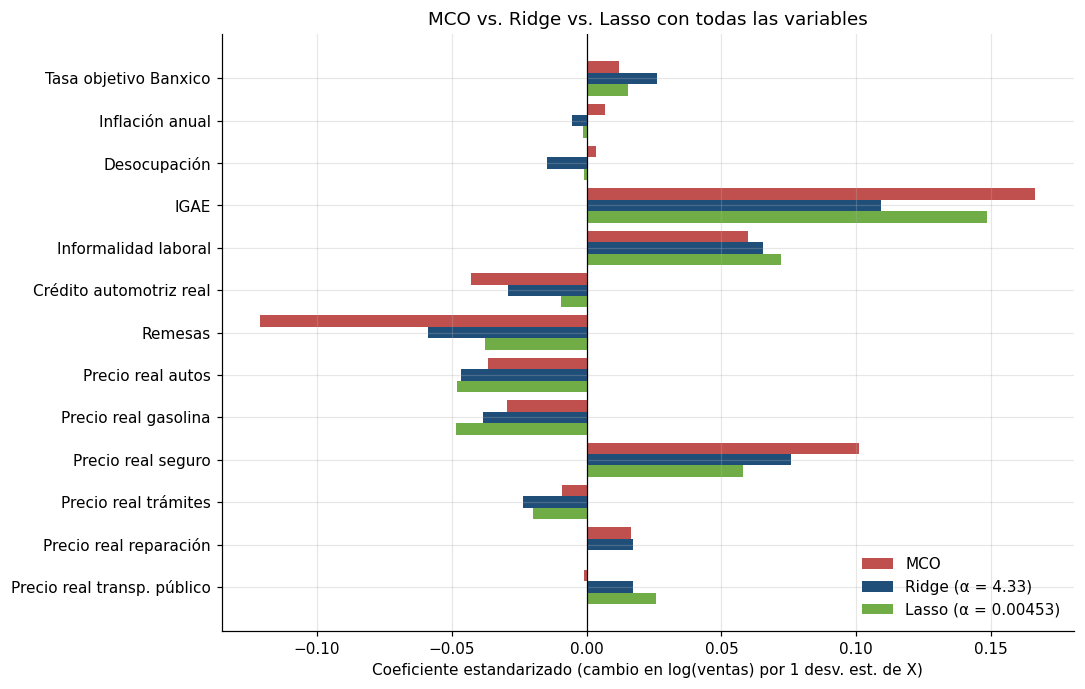

Lasso eliminó: Precio real reparación


,MCO,Ridge,Lasso,Esperado,¿Lasso la elimina?
Tasa objetivo Banxico,0.0120,0.0261,0.0154,-,No
Inflación anual,0.0068,-0.0054,-0.0014,-,No
Desocupación,0.0036,-0.0148,-0.0008,-,No
IGAE,0.1664,0.1092,0.1483,+,No
Informalidad laboral,0.0598,0.0654,0.0721,-,No
Crédito automotriz real,-0.0428,-0.0290,-0.0096,+,No
Remesas,-0.1210,-0.0589,-0.0377,+,No
Precio real autos,-0.0367,-0.0467,-0.0480,-,No
Precio real gasolina,-0.0295,-0.0384,-0.0482,-,No
Precio real seguro,0.1009,0.0759,0.0578,-,No


In [19]:
# --- Comparación de coeficientes estandarizados: MCO vs. Ridge vs. Lasso ---
# Cada coeficiente = cambio en log(ventas) por 1 desviación estándar de X.
comp = pd.DataFrame({
    "MCO": pd.Series(mco_std.coef_, index=Z.columns),
    "Ridge": pd.Series(ridge_cv.coef_, index=Z.columns),
    "Lasso": pd.Series(lasso_cv.coef_, index=Z.columns),
}).loc[XS_REG]
comp["Esperado"] = [CATALOGO[v][2] for v in XS_REG]
comp["¿Lasso la elimina?"] = np.where(comp["Lasso"].abs() < 1e-8, "Sí", "No")
comp.index = [NOMBRE[v] for v in XS_REG]
comp.round(4).to_csv("tablas/ridge_lasso_coeficientes.csv")

fig, ax = plt.subplots(figsize=(10, 0.45 * len(comp) + 1.2))
y = np.arange(len(comp))
ax.barh(y - 0.27, comp["MCO"], height=0.27, color="#c0504d", label="MCO")
ax.barh(y, comp["Ridge"], height=0.27, color="#1f4e79", label=f"Ridge (α = {ridge_cv.alpha_:.3g})")
ax.barh(y + 0.27, comp["Lasso"], height=0.27, color="#70ad47", label=f"Lasso (α = {lasso_cv.alpha_:.3g})")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(comp.index)
ax.invert_yaxis()
ax.set_xlabel("Coeficiente estandarizado (cambio en log(ventas) por 1 desv. est. de X)")
ax.set_title("MCO vs. Ridge vs. Lasso con todas las variables")
ax.legend(frameon=False, loc="lower right")
plt.show()

print("Lasso eliminó:", ", ".join(comp.index[comp["¿Lasso la elimina?"] == "Sí"]) or "ninguna")
comp.round(4)

### 7.2 Trayectorias de los coeficientes

Estas gráficas muestran qué le pasa a cada coeficiente conforme aumentamos el castigo α, de izquierda (casi sin castigo, igual que MCO) a derecha (castigo muy fuerte). El eje horizontal está en escala logarítmica para que quepan valores muy pequeños y muy grandes, y la línea punteada marca el α que elegimos por validación cruzada.

En Ridge, todos los coeficientes se encogen poco a poco hacia cero, pero ninguno llega a cero; las remesas son las que más rápido se encogen, otra señal de que su coeficiente en MCO estaba inflado.

En Lasso, las variables van saliendo del modelo una por una conforme sube el castigo. Las que resisten más antes de salir son las que más información aportan. en nuestro caso, el IGAE, el precio de autos y la informalidad.

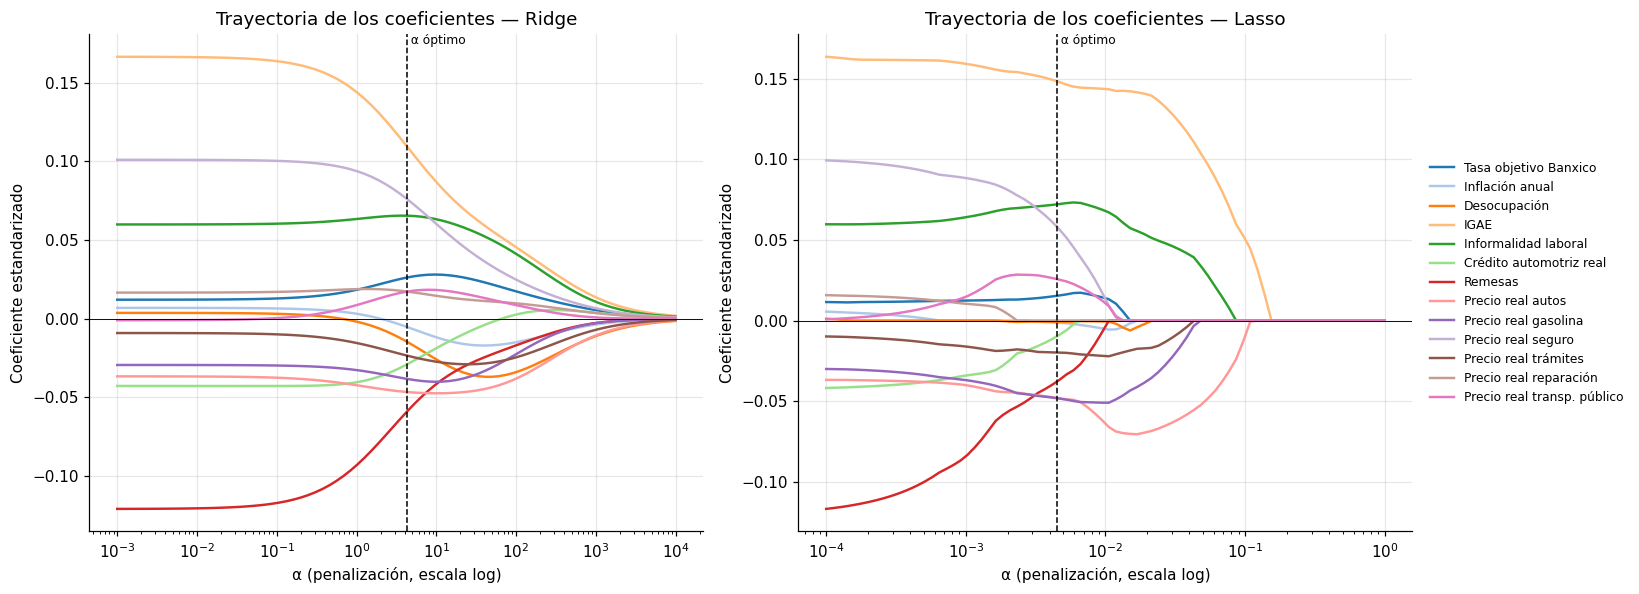

In [20]:
# --- Trayectorias de regularización ---
# Cómo se encoge cada coeficiente cuando aumenta la penalización (alpha).
# Ridge: las variables correlacionadas se encogen JUNTAS y nunca llegan a cero.
# Lasso: van saliendo del modelo una por una; las que sobreviven más son las que más aportan.
def trayectoria(modelo, alphas):
    coefs = []
    for a in alphas:
        m = modelo(alpha=a, max_iter=100000) if modelo is Lasso else modelo(alpha=a)
        coefs.append(m.fit(Z, y_reg).coef_[:len(XS_REG)])
    return pd.DataFrame(coefs, index=alphas, columns=[NOMBRE[v] for v in XS_REG])

tray_ridge = trayectoria(Ridge, np.logspace(-3, 4, 80))
tray_lasso = trayectoria(Lasso, np.logspace(-4, 0, 80))

paleta = sns.color_palette("tab20", len(XS_REG))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, tray, nombre, a_opt in [(axes[0], tray_ridge, "Ridge", ridge_cv.alpha_),
                                (axes[1], tray_lasso, "Lasso", lasso_cv.alpha_)]:
    for color, col in zip(paleta, tray.columns):
        ax.plot(tray.index, tray[col], color=color, lw=1.6, label=col)
    ax.axvline(a_opt, color="black", ls="--", lw=1)
    ax.text(a_opt, ax.get_ylim()[1], " α óptimo", va="top", fontsize=8)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xscale("log")
    ax.set_xlabel("α (penalización, escala log)")
    ax.set_ylabel("Coeficiente estandarizado")
    ax.set_title(f"Trayectoria de los coeficientes — {nombre}")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

### 7.3 ¿Cuál predice mejor fuera de muestra?

Dividimos la muestra en 5 bloques de tiempo: el modelo se estima con los meses anteriores a cada bloque y se usa para predecir ese bloque. El error se mide con el RMSE (raíz del error cuadrático medio), que resume qué tan lejos quedan las predicciones de las ventas reales; entre más bajo, mejor. Como las ventas están en logaritmo, un RMSE de 0.20 equivale aproximadamente a equivocarse en 20% en promedio.

Ridge tiene el menor error (0.205), seguido de Lasso (0.208) y MCO (0.211). La diferencia es pequeña, así que la ventaja principal de la regularización no es predecir mejor, sino dar coeficientes más estables.

Además, el error cambia mucho entre bloques: los tres modelos se equivocan más en los periodos con cambios bruscos, como el COVID y la recuperación posterior.

In [21]:
# --- ¿Predicen mejor fuera de muestra? ---
# Error de pronóstico (RMSE de log(ventas)) en validación cruzada temporal: menor es mejor.
modelos_pred = {
    "MCO (todas las variables)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=ridge_cv.alpha_)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=lasso_cv.alpha_, max_iter=100000)),
}
filas = []
for nombre, m in modelos_pred.items():
    rmse = -cross_val_score(m, X_reg, y_reg, cv=CV, scoring="neg_root_mean_squared_error")
    filas.append({"Modelo": nombre, "RMSE promedio": round(rmse.mean(), 4), "RMSE por bloque": np.round(rmse, 3)})
pred = pd.DataFrame(filas)
pred[["Modelo", "RMSE promedio"]].to_csv("tablas/ridge_lasso_pronostico.csv", index=False)
pred

,Modelo,RMSE promedio,RMSE por bloque
0,MCO (todas las variables),0.2112,"[0.134, 0.162, 0.136, 0.503, 0.121]"
1,Ridge,0.2047,"[0.109, 0.45, 0.095, 0.229, 0.14]"
2,Lasso,0.2081,"[0.076, 0.486, 0.184, 0.217, 0.077]"


Consideramos también Elastic Net, que combina las penalizaciones de Ridge y Lasso. Al probarlo, la validación cruzada eligió una mezcla casi totalmente tipo Ridge (proporción L1 de 0.05), y su error de pronóstico fue mayor que el de los otros tres modelos (RMSE de 0.232). Como no cambia ninguna conclusión y Ridge ya captura su efecto, decidimos no incluirlo en el análisis.

## 8. Para exportar tablas

Las tablas se guardan en `tablas/` y se descargan en `tablas_proyecto.zip` para pegarlas en el informe.

In [22]:
resumen = {
    "observaciones": int(res[MODELO_FINAL].nobs),
    "periodo": f"{df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}",
    "modelo_final": MODELO_FINAL,
    "rezagos_newey_west": REZAGOS_HAC,
    "r2": {m: round(r.rsquared, 4) for m, r in res.items()},
    "r2_ajustado": {m: round(r.rsquared_adj, 4) for m, r in res.items()},
    "coeficientes_modelo_final": {NOMBRE[v]: {"beta": round(res[MODELO_FINAL].params[v], 5),
                                              "ee_hac": round(res[MODELO_FINAL].bse[v], 5),
                                              "p": round(res[MODELO_FINAL].pvalues[v], 4)}
                                  for v in MODELOS[MODELO_FINAL]},
    "vif_max": {m: round(float(vifs[m].max()), 1) for m in vifs.columns},
    "ridge_alpha": round(float(ridge_cv.alpha_), 5),
    "lasso_alpha": round(float(lasso_cv.alpha_), 6),
    "lasso_elimina": list(comp.index[comp["¿Lasso la elimina?"] == "Sí"]),
}
with open("tablas/resultados.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)
print(json.dumps(resumen, ensure_ascii=False, indent=2))

import zipfile
with zipfile.ZipFile("tablas_proyecto.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in sorted(os.listdir("tablas")):
        z.write(os.path.join("tablas", archivo))
try:
    from google.colab import files
    files.download("tablas_proyecto.zip")
except ImportError:
    print("Archivo creado: tablas_proyecto.zip")

{
  "observaciones": 120,
  "periodo": "2016-01 a 2025-12",
  "modelo_final": "M4 Reducido",
  "rezagos_newey_west": 4,
  "r2": {
    "M1 Base": 0.7212,
    "M2 Ingreso y crédito": 0.8845,
    "M3 Completo": 0.9472,
    "M4 Reducido": 0.9358
  },
  "r2_ajustado": {
    "M1 Base": 0.6779,
    "M2 Ingreso y crédito": 0.8626,
    "M3 Completo": 0.9332,
    "M4 Reducido": 0.9221
  },
  "coeficientes_modelo_final": {
    "Tasa objetivo Banxico": {
      "beta": 0.01404,
      "ee_hac": 0.00675,
      "p": 0.0375
    },
    "Inflación anual": {
      "beta": -0.01024,
      "ee_hac": 0.00573,
      "p": 0.0742
    },
    "IGAE": {
      "beta": 0.04332,
      "ee_hac": 0.00481,
      "p": 0.0
    },
    "Informalidad laboral": {
      "beta": 0.03279,
      "ee_hac": 0.01199,
      "p": 0.0062
    },
    "Crédito automotriz real": {
      "beta": -0.00024,
      "ee_hac": 0.00064,
      "p": 0.7037
    },
    "Remesas": {
      "beta": -0.09337,
      "ee_hac": 0.02912,
      "p": 0.0013
   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusiones y limitaciones

Las ventas de vehículos ligeros se asocian sobre todo con la actividad económica y el costo de usar un auto: un punto más del IGAE se asocia con ventas 4.4% mayores, y un punto más en el precio real de la gasolina con ventas 1.0% menores.

Ambos resultados se mantienen en todas las pruebas de robustez y con Ridge y Lasso. La multicolinealidad sí dificulta responder la pregunta: al pasar de 4 a 13 variables, la tasa, la inflación y la desocupación pierden significancia y cambian de signo, aunque el R² sube a 0.95.

Quitar variables redundantes y usar Ridge la reducen, pero no la eliminan, porque varias series comparten tendencia.

Estos resultados son asociaciones, no efectos causales. Las principales limitaciones son la posible causalidad inversa entre la tasa y las ventas, variables omitidas como la escasez de chips de 2021–2022, la tendencia común de varias series y el cambio de encuesta de empleo del INEGI en 2020.